<a href="https://colab.research.google.com/github/JulTob/Modelling/blob/main/GLM/GLM_1_Tratamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Caso 1 — OsteoRed: fractura durante el seguimiento

Trabajamos con una cohorte simulada de pacientes de OsteoRed.

Cada fila representa una paciente. La variable `ever` indica si
se observó una fractura durante su seguimiento:

- `ever = 1`: se observó una fractura.
- `ever = 0`: terminó su observación sin una fractura registrada.

Nuestro primer objetivo es conocer la estructura de los datos
y calcular qué proporción de pacientes presentó una fractura.

In [44]:
url_cohorte <- paste0(
    "https://raw.githubusercontent.com/JulTob/Modelling/main/",
    "GLM/Datos/Osteored/cohorte.rds"
    )

download.file(
    url_cohorte,
    destfile = "cohorte.rds",
    mode = "wb"
    )

cohorte <- readRDS("cohorte.rds")

In [45]:
dim(cohorte)
    #--> n pacientes · m variables.
head(cohorte)

[1] 803   9

,id,centro,x1,x2,tiempo,evento,ever,clase_nom,sever_ord
,<int>,<fct>,<dbl>,<int>,<int>,<int>,<int>,<fct>,<ord>
1,1,1,0.0605002,0,3,0,0,C,Leve
2,2,1,0.6324950,1,6,0,0,C,Moderado
3,3,1,-0.7137340,1,6,0,0,A,Moderado
4,4,1,-0.7710438,1,6,0,0,C,Leve
5,5,1,0.5808291,1,5,0,0,B,Moderado
6,6,1,0.2369371,1,5,0,0,A,Leve


- `id` — identifica a la paciente.
- `centro` — identifica su clínica.
- `x1` — fragilidad ósea, expresada como una variable continua estandarizada.
- `x2` — tratamiento preventivo: 0 si no lo recibe y 1 si lo recibe.
- `ever` — indica si se observó una fractura durante su seguimiento.

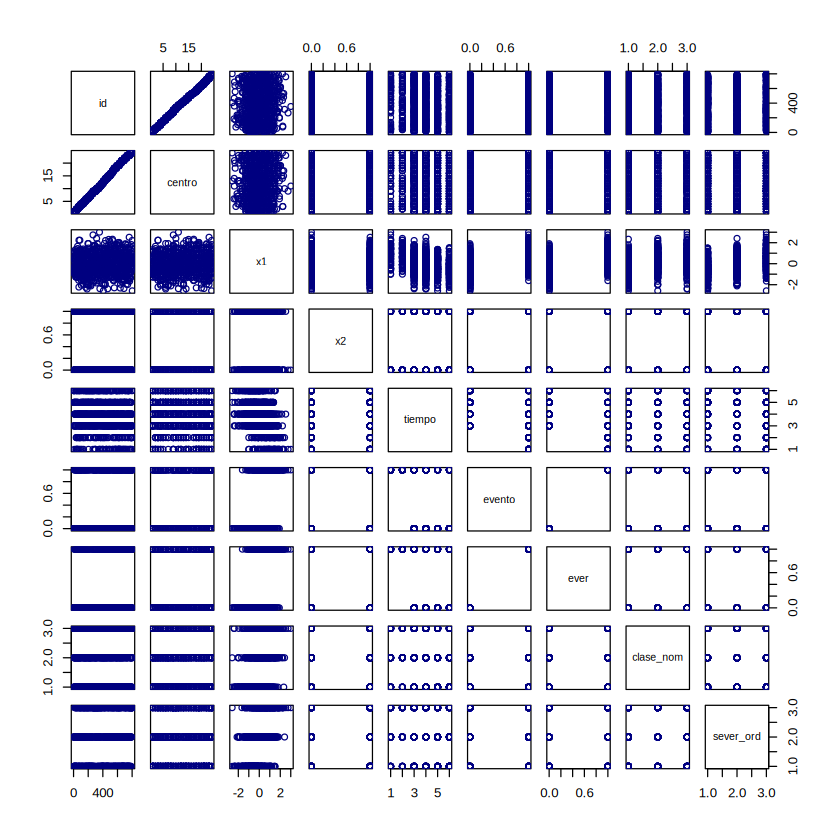

In [46]:
plot(cohorte, col= "Navy")

In [47]:
table(
    cohorte$ever,
    useNA = "ifany") # valores ausentes visibles

mean(cohorte$ever)


  0   1 
556 247 

[1] 0.3075965

En esta cohorte, se observó una fractura durante el seguimiento de `247` de las `803` pacientes, aproximadamente el `30,76 %`.

# Puntos Clave:
- Cada fila en `cohorte`representa una paciente a lo largo del estudio.
- `Ever` es un valor binario (booleano) indicando la presencia (positiva:=1) de fractura, o su ausencia (negativa:=0).
- `mean(ever)` es la proporción observada de fractura a lo largo del estudio. Este valor por sí mismo no identifica factores con relación en el estudio.  

----

# $\color{skyblue}✙$  ¿Cómo se distribuye la fragilidad ósea entre las pacientes con y sin fractura observada, dentro de cada grupo de tratamiento?



In [48]:
# Instalar ggplot2
if (!requireNamespace("ggplot2", quietly = TRUE)) {
    install.packages(
        "ggplot2",
        repos = "https://cloud.r-project.org"
        )
    }

library(ggplot2)

# Preparar etiquetas para el gráfico.
datos_grafico <- transform(
    cohorte,

    fractura = factor(
        ever,
        levels = c(0, 1),
        labels = c("No", "Sí")
        ),

    tratamiento = factor(
        x2,
        levels = c(0, 1),
        labels = c("Sin tratamiento", "Con tratamiento")
        )
    )


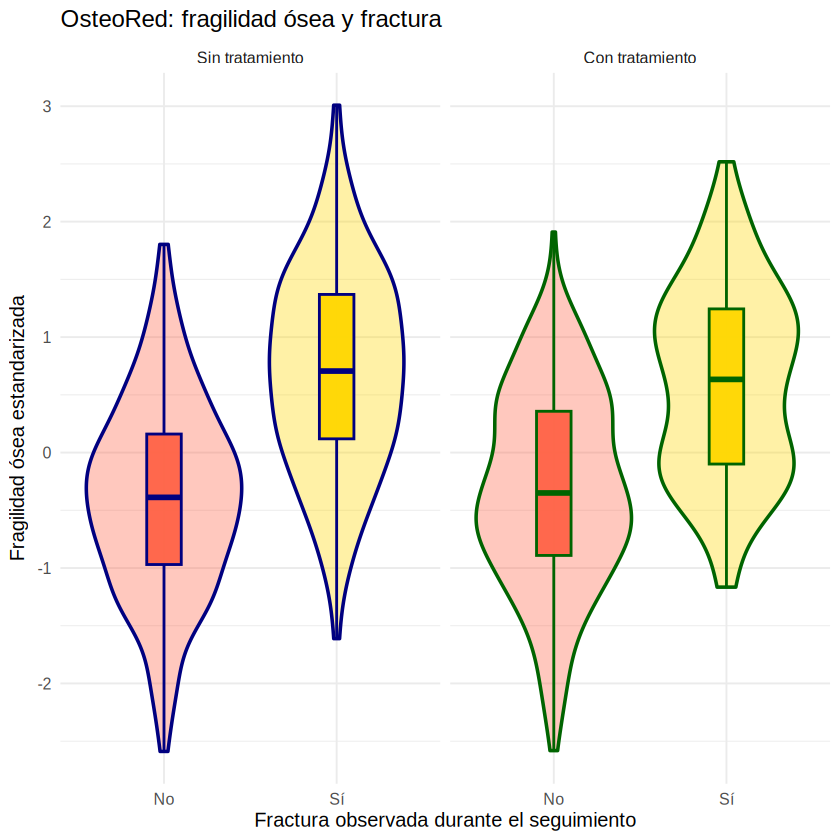

In [49]:
ggplot(
    datos_grafico,
    aes(
        x = fractura,
        y = x1,
        fill = fractura,
        colour = tratamiento
        )
    ) + geom_violin(
        alpha = 0.35,
        linewidth = 1.0
    ) + geom_boxplot(
        width = 0.2,
        alpha = 0.95,
        linewidth = 0.8,
        outlier.alpha = 0.4,
        outlier.size = 1.2
    ) + facet_wrap(
        ~ tratamiento
    ) + scale_fill_manual(
        values = c(
            "No" = "Tomato",
            "Sí" = "Gold"
            )
    ) + scale_colour_manual(
        values = c(
            "Sin tratamiento" = "Navy",
            "Con tratamiento" = "DarkGreen"
            )
    ) + labs(
        title = "OsteoRed: fragilidad ósea y fractura",
        x = "Fractura observada durante el seguimiento",
        y = "Fragilidad ósea estandarizada"
    ) + guides(
        fill = "none",
        colour = "none"
    ) + theme_minimal(
        base_size = 12)


### Observaciones:
- Fragilidad, más alta en pacientes con factura. Los rangos tienen solapamiento, con areas de clara diferenciación.
- Poca diferencia visual entre Con/Sin Tratamiento.


-----

In [50]:
# Intervalos de fragilidad que cubren todos los datos.
ancho <- 0.25

cortes <- seq(
    floor(min(datos_grafico$x1) / ancho) * ancho,
    ceiling(max(datos_grafico$x1) / ancho) * ancho,
    by = ancho
    )

datos_tramos <- transform(
    datos_grafico,
    tramo = cut(x1, breaks = cortes, include.lowest = TRUE),
    n = 1L
    )

# Sumar las cantidades dentro de cada tramo y tratamiento.
resumen_tramos <- aggregate(
    cbind(  n,
            fracturas = ever,
            fragilidad = x1) ~
        tramo + tratamiento,
    data = datos_tramos,
    FUN = sum,
    na.action = na.fail
    )

# Obtener la posición y la proporción de cada grupo.
resumen_tramos <- transform(
    resumen_tramos,
    fragilidad_u = fragilidad / n,
    fracturas_u = fracturas / n
    )

resumen_tramos

tramo,tratamiento,n,fracturas,fragilidad,fragilidad_u,fracturas_u
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"[-2.75,-2.5]",Sin tratamiento,1,0,-2.588764,-2.5887644,0.00000000
"(-2.5,-2.25]",Sin tratamiento,3,0,-7.169042,-2.3896808,0.00000000
"(-2.25,-2]",Sin tratamiento,5,0,-10.425807,-2.0851614,0.00000000
"(-2,-1.75]",Sin tratamiento,6,0,-11.565117,-1.9275196,0.00000000
"(-1.75,-1.5]",Sin tratamiento,10,1,-16.169814,-1.6169814,0.10000000
"(-1.5,-1.25]",Sin tratamiento,21,1,-28.428368,-1.3537318,0.04761905
"(-1.25,-1]",Sin tratamiento,25,1,-28.157338,-1.1262935,0.04000000
"(-1,-0.75]",Sin tratamiento,28,4,-24.492567,-0.8747345,0.14285714
"(-0.75,-0.5]",Sin tratamiento,39,7,-24.787215,-0.6355696,0.17948718


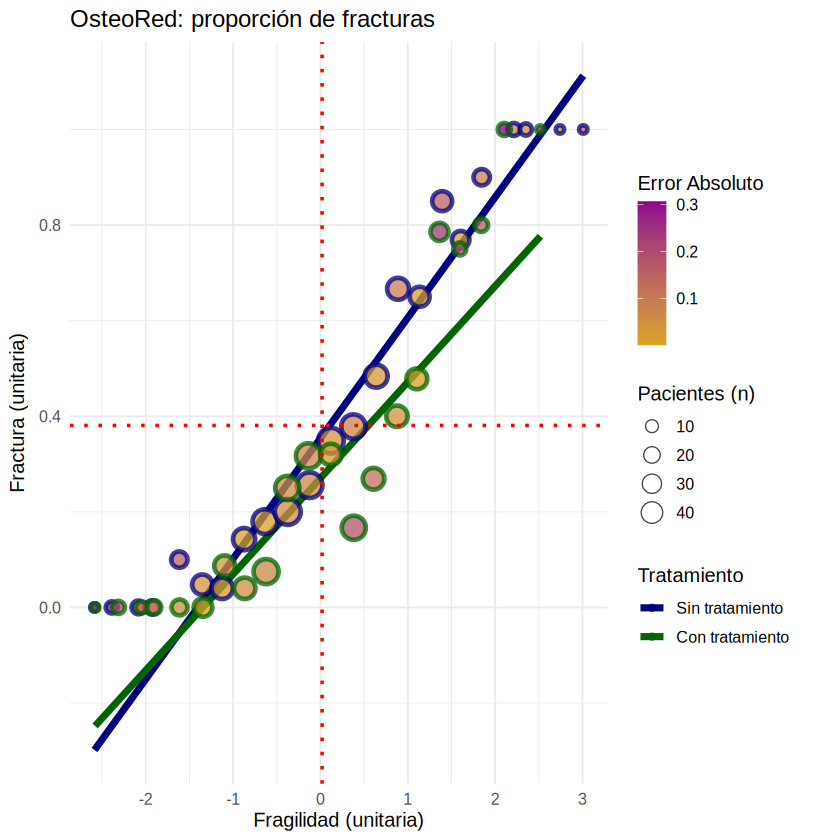

In [51]:
# 1. Calcular los modelos lineales por tratamiento para obtener los residuos (errores)
resumen_tramos$prediccion <- NA

for (trata in unique(resumen_tramos$tratamiento)) {
    indices <- resumen_tramos$tratamiento == trata
    modelo <- lm(fracturas_u ~ fragilidad_u, data = resumen_tramos[indices, ], weights = resumen_tramos$n[indices])
    resumen_tramos$prediccion[indices] <- predict(modelo, newdata = resumen_tramos[indices, ])
}

# El error (residuo) con respecto a su línea
resumen_tramos$error <- resumen_tramos$fracturas_u - resumen_tramos$prediccion
resumen_tramos$error_abs <- abs(resumen_tramos$error)

# Calcular las medias totales de fragilidad_u y fracturas_u
media_fragilidad <- mean(resumen_tramos$fragilidad_u, na.rm = TRUE)
media_fracturas <- mean(resumen_tramos$fracturas_u, na.rm = TRUE)

# 2. Generar el gráfico mapeando el fill al error absoluto
grafico_proporciones <- ggplot(
        resumen_tramos,
        aes(    x = fragilidad_u,
                y = fracturas_u,
                colour = tratamiento
                )
        ) +
    geom_smooth(    aes(weight = n),
                    method = "lm",
                    formula = y ~ x,
                    se = FALSE,
                    linewidth = 2,
                    alpha = 0.5
        ) +
    geom_point( aes(
                    size = n,
                    stroke = 2,
                    fill = error_abs
                    ),
                shape = 21,
                alpha = 0.75
        ) +
    geom_vline(
        xintercept = media_fragilidad,
        linetype = "dotted",
        colour = "red",
        linewidth = 1
    ) +
    geom_hline(
        yintercept = media_fracturas,
        linetype = "dotted",
        colour = "red",
        linewidth = 1
    ) +
    scale_colour_manual(    values = c(
            "Sin tratamiento" = "Navy",
            "Con tratamiento" = "DarkGreen"
            )
        ) +
    scale_fill_gradient(
            low = "goldenrod",
            high = "darkmagenta"
        ) +
    labs(   title = "OsteoRed: proporción de fracturas",
            x = "Fragilidad (unitaria)",
            y = "Fractura (unitaria)",
            colour = "Tratamiento",
            fill = "Error Absoluto",
            size = "Pacientes (n)"
            ) +
    theme_minimal(base_size = 12)

grafico_proporciones

In [53]:
mean(resumen_tramos$fracturas_u, na.rm = TRUE)

[1] 0.3807196